<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Ejercicios/Soluciones/02_Taller_Espacios_Vectoriales_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Taller práctico: espacios vectoriales (solución)</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Instrucciones</h2>

Solución de referencia del taller [`02_Taller_Espacios_Vectoriales.ipynb`](../02_Taller_Espacios_Vectoriales.ipynb).

Hay muchas soluciones válidas: esta es una de ellas. Compara tus resultados y, sobre todo, tus conclusiones.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Ejercicio 1. Medidas de similitud desde cero</span>](#ejercicio-1)
- [<span style="color: #005C99;">Ejercicio 2. TF-IDF sublineal desde cero</span>](#ejercicio-2)
- [<span style="color: #005C99;">Ejercicio 3. Un buscador y su evaluación</span>](#ejercicio-3)
- [<span style="color: #005C99;">Ejercicio 4. Clasificación en el espacio vectorial</span>](#ejercicio-4)
- [<span style="color: #005C99;">Ejercicio 5. Vectores de palabras y el tamaño de la ventana</span>](#ejercicio-5)
- [<span style="color: #005C99;">Ejercicio 6. Tópicos latentes y visualización</span>](#ejercicio-6)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scikit-learn scipy nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

import nltk
from nltk.corpus import reuters

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)

nltk.download("reuters", quiet=True)

# Usamos noticias con una sola categoría, de 8 temas
CATEGORIAS = ["crude", "trade", "money-fx", "interest", "money-supply", "ship", "sugar", "coffee"]
docs = [f for f in reuters.fileids() if len(reuters.categories(f)) == 1 and reuters.categories(f)[0] in CATEGORIAS]

train_ids = [f for f in docs if f.startswith("training/")]
test_ids = [f for f in docs if f.startswith("test/")]

X_train_txt = [reuters.raw(f) for f in train_ids]
X_test_txt = [reuters.raw(f) for f in test_ids]
y_train = np.array([reuters.categories(f)[0] for f in train_ids])
y_test = np.array([reuters.categories(f)[0] for f in test_ids])

print(f"Entrenamiento: {len(train_ids)} | Prueba: {len(test_ids)}")
print(pd.Series(y_train).value_counts().to_dict())
print("\nEjemplo:\n", X_train_txt[0][:400])

Entrenamiento: 1334 | Prueba: 476
{'crude': 253, 'trade': 250, 'money-fx': 222, 'interest': 191, 'money-supply': 123, 'ship': 108, 'sugar': 97, 'coffee': 90}

Ejemplo:
 N.Z. TRADING BANK DEPOSIT GROWTH RISES SLIGHTLY
  New Zealand's trading bank seasonally
  adjusted deposit growth rose 2.6 pct in January compared with a
  rise of 9.4 pct in December, the Reserve Bank said.
      Year-on-year total deposits rose 30.6 pct compared with a
  26.3 pct increase in the December year and 34.5 pct rise a year
  ago period, it said in its weekly statistical release.
     


---

<a id="ejercicio-1"></a>
<h2 style="color: #007ACC;">Ejercicio 1. Medidas de similitud desde cero</h2>

**Objetivo:** implementar las medidas de similitud con NumPy y comprobar su relación cuando los vectores están normalizados.

1. Implementa `producto_punto(a, b)`, `norma(a)`, `similitud_coseno(a, b)` y `distancia_euclidiana(a, b)` usando solo operaciones de NumPy (sin `np.linalg.norm` ni funciones de scikit-learn).
2. Verifícalas contra `cosine_similarity` y `euclidean_distances` de scikit-learn con los vectores de conteo de dos noticias de entrenamiento (`CountVectorizer`).
3. Normaliza los dos vectores a norma 1 y comprueba numéricamente la identidad $\|\mathbf{a} - \mathbf{b}\|^2 = 2 - 2\cos(\mathbf{a}, \mathbf{b})$. Demuéstrala algebraicamente en una celda markdown.
4. ¿Qué consecuencia práctica tiene esta identidad para un buscador que usa vectores TF-IDF normalizados?

In [3]:
def producto_punto(a, b):
    return float(np.sum(a * b))


def norma(a):
    return np.sqrt(producto_punto(a, a))


def similitud_coseno(a, b):
    return producto_punto(a, b) / (norma(a) * norma(b))


def distancia_euclidiana(a, b):
    return norma(a - b)


cv = CountVectorizer().fit(X_train_txt)
a, b = cv.transform(X_train_txt[:2]).toarray().astype(float)

print(f"Coseno:     propio={similitud_coseno(a, b):.6f} | sklearn={cosine_similarity([a], [b])[0, 0]:.6f}")
print(f"Euclidiana: propia={distancia_euclidiana(a, b):.6f} | sklearn={euclidean_distances([a], [b])[0, 0]:.6f}")

an, bn = a / norma(a), b / norma(b)
print(f"\n||a-b||^2 = {distancia_euclidiana(an, bn) ** 2:.6f}  |  2 - 2cos = {2 - 2 * similitud_coseno(an, bn):.6f}")

Coseno:     propio=0.236021 | sklearn=0.236021
Euclidiana: propia=17.663522 | sklearn=17.663522

||a-b||^2 = 1.527958  |  2 - 2cos = 1.527958


**Demostración.** Si $\|\mathbf{a}\| = \|\mathbf{b}\| = 1$:

$$\|\mathbf{a} - \mathbf{b}\|^2 = (\mathbf{a} - \mathbf{b}) \cdot (\mathbf{a} - \mathbf{b}) = \|\mathbf{a}\|^2 - 2\,\mathbf{a} \cdot \mathbf{b} + \|\mathbf{b}\|^2 = 2 - 2\,\mathbf{a} \cdot \mathbf{b} = 2 - 2\cos(\mathbf{a}, \mathbf{b})$$

porque con vectores unitarios $\cos(\mathbf{a}, \mathbf{b}) = \mathbf{a} \cdot \mathbf{b}$.

**Consecuencia práctica:** con vectores normalizados, la distancia euclidiana es una función decreciente del coseno, así que ambos producen **el mismo ranking** de resultados. Además, el coseno se reduce a un **producto punto**, que es muy eficiente: todas las similitudes entre una consulta y la colección se obtienen con una multiplicación matriz-vector dispersa. Por eso `TfidfVectorizer` normaliza por defecto y por eso muchas librerías de búsqueda vectorial usan el producto interno.

---

<a id="ejercicio-2"></a>
<h2 style="color: #007ACC;">Ejercicio 2. TF-IDF sublineal desde cero</h2>

**Objetivo:** implementar TF-IDF sobre matrices dispersas, incluida la variante sublineal, y validarla contra scikit-learn.

En documentos largos, que una palabra aparezca 20 veces no la hace 20 veces más importante que si aparece una vez. La variante **sublineal** amortigua la frecuencia con un logaritmo:

$$\text{tf}_{\text{sub}}(t, d) = \begin{cases} 1 + \log \text{tf}(t, d) & \text{si } \text{tf}(t, d) > 0 \\ 0 & \text{en otro caso} \end{cases}$$

1. Con `CountVectorizer(stop_words="english")` obtén la matriz de conteos de entrenamiento `C_train` (dispersa).
2. Implementa `ajustar_idf(C)` que devuelva el vector IDF suavizado de scikit-learn: $\ln\frac{1 + N}{1 + \text{df}(t)} + 1$.
3. Implementa `transformar_tfidf(C, idf, sublineal=True)` que devuelva una matriz **dispersa** normalizada por filas (norma L2). Pista: en una matriz `csr`, `C.data` contiene solo los valores no nulos, así que puedes aplicar el logaritmo sobre `C.data` directamente.
4. Verifica que tu resultado coincide con `TfidfVectorizer(stop_words="english", sublinear_tf=True)`.
5. Para una noticia larga, compara los 8 términos con mayor peso con TF lineal y con TF sublineal. ¿Qué cambia?

In [4]:
cv = CountVectorizer(stop_words="english")
C_train = cv.fit_transform(X_train_txt).tocsr().astype(float)
terminos = cv.get_feature_names_out()


def ajustar_idf(C):
    N = C.shape[0]
    df = np.bincount(C.indices, minlength=C.shape[1])  # documentos en los que aparece cada término
    return np.log((1 + N) / (1 + df)) + 1


def transformar_tfidf(C, idf, sublineal=True):
    T = C.copy().astype(float)
    if sublineal:
        T.data = 1 + np.log(T.data)
    T = T @ sparse.diags(idf)
    return normalize(T, norm="l2")


idf = ajustar_idf(C_train)
T_propia = transformar_tfidf(C_train, idf)
T_sk = TfidfVectorizer(stop_words="english", sublinear_tf=True).fit_transform(X_train_txt)

print("Forma:", T_propia.shape, "| ¿dispersa?", sparse.issparse(T_propia))
print("Diferencia máxima con scikit-learn:", abs(T_propia - T_sk).max())

Forma: (1334, 10973) | ¿dispersa? True
Diferencia máxima con scikit-learn: 1.942890293094024e-16


In [5]:
i = int(np.argmax(C_train.sum(axis=1)))  # la noticia más larga
T_lineal = transformar_tfidf(C_train[i], idf, sublineal=False).toarray()[0]
T_sub = T_propia[i].toarray()[0]

print(f"Noticia {train_ids[i]} ({int(C_train[i].sum())} tokens, tema: {y_train[i]})\n")
pd.DataFrame({
    "TF lineal": terminos[np.argsort(T_lineal)[::-1][:8]],
    "TF sublineal": terminos[np.argsort(T_sub)[::-1][:8]],
})

Noticia training/5214 (627 tokens, tema: sugar)



,TF lineal,TF sublineal
0,sugar,ha
1,beet,beet
2,ha,plantings
3,plantings,planting
4,tonnes,sugar
5,000,licht
6,year,hectares
7,ec,sowings


**Interpretación:** con TF lineal, las pocas palabras que más se repiten acaparan casi todo el peso del vector. Con TF sublineal, una palabra que aparece 20 veces solo pesa unas 4 veces más que una que aparece una vez ($1 + \ln 20 \approx 4$), así que suben en el ranking términos menos repetidos pero más específicos (con IDF alto). El vector representa mejor la **variedad** de temas del documento.

---

<a id="ejercicio-3"></a>
<h2 style="color: #007ACC;">Ejercicio 3. Un buscador y su evaluación</h2>

**Objetivo:** construir un buscador por similitud coseno y comparar representaciones con una métrica cuantitativa (precisión@k).

No tenemos juicios de relevancia, pero podemos usar las categorías como aproximación: **un resultado es relevante si tiene la misma categoría que la consulta**. Usaremos cada noticia de prueba como consulta contra la colección de entrenamiento.

$$\text{precisión@}k = \frac{\#\{\text{resultados relevantes entre los primeros } k\}}{k}$$

1. Implementa `precision_at_k(Q, D, y_q, y_d, k)` que, dadas las matrices de consultas `Q` y de documentos `D`, calcule la precisión@k promedio sobre todas las consultas (usa `cosine_similarity`, que acepta matrices dispersas).
2. Compara la precisión@10 de estas representaciones (ajustadas solo con entrenamiento):
   - conteos crudos (`CountVectorizer()`),
   - conteos sin stopwords,
   - TF-IDF sin stopwords,
   - TF-IDF sin stopwords y sublineal,
   - TF-IDF con unigramas y bigramas (`ngram_range=(1, 2)`, `min_df=2`).
3. Presenta los resultados en una tabla y una gráfica de barras.
4. Implementa `buscar(consulta, k=5)` con la mejor representación y pruébala con al menos tres consultas propias.
5. ¿Qué representación funciona mejor y por qué?

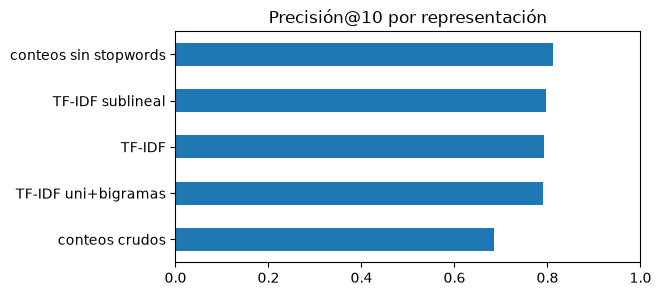

,precisión@10
conteos crudos,0.686
TF-IDF uni+bigramas,0.791
TF-IDF,0.793
TF-IDF sublineal,0.797
conteos sin stopwords,0.812


In [6]:
def precision_at_k(Q, D, y_q, y_d, k=10):
    sims = cosine_similarity(Q, D)
    top = np.argsort(-sims, axis=1)[:, :k]
    return float(np.mean(y_d[top] == y_q[:, None]))


representaciones = {
    "conteos crudos": CountVectorizer(),
    "conteos sin stopwords": CountVectorizer(stop_words="english"),
    "TF-IDF": TfidfVectorizer(stop_words="english"),
    "TF-IDF sublineal": TfidfVectorizer(stop_words="english", sublinear_tf=True),
    "TF-IDF uni+bigramas": TfidfVectorizer(stop_words="english", sublinear_tf=True, ngram_range=(1, 2), min_df=2),
}

res = {}
for nombre, vec in representaciones.items():
    D = vec.fit_transform(X_train_txt)
    Q = vec.transform(X_test_txt)
    res[nombre] = precision_at_k(Q, D, y_test, y_train, k=10)

res = pd.Series(res, name="precisión@10").sort_values()
res.plot.barh(figsize=(6, 3), xlim=(0, 1), title="Precisión@10 por representación")
plt.show()
res.round(3).to_frame()

In [7]:
mejor_vec = representaciones[res.idxmax()]
D_mejor = mejor_vec.fit_transform(X_train_txt)


def buscar(consulta, k=5):
    sims = cosine_similarity(mejor_vec.transform([consulta]), D_mejor).ravel()
    idx = np.argsort(-sims)[:k]
    return pd.DataFrame({
        "similitud": sims[idx].round(3),
        "categoría": y_train[idx],
        "titular": [X_train_txt[i].strip().split("\n")[0][:90] for i in idx],
    })


pd.set_option("display.max_colwidth", 100)
for consulta in ["opec oil production cuts", "coffee export quotas brazil", "federal reserve interest rates"]:
    print(f"Consulta: {consulta}")
    display(buscar(consulta))

Consulta: opec oil production cuts


,similitud,categoría,titular
0,0.556,crude,OPEC MAY HAVE TO MEET TO FIRM PRICES - ANALYSTS
1,0.452,crude,SAUDI OIL MINISTER SEES NO NEED TO ALTER OPEC PACT
2,0.451,crude,KUWAIT SAYS NO OPEC MEMBER VIOLATING OUTPUT QUOTA
3,0.446,crude,SAUDI OIL MINISTER SEES NO NEED TO ALTER PACT
4,0.419,crude,SAUDI SUCCESS SEEN IN CURBING OPEC PRODUCTION


Consulta: coffee export quotas brazil


,similitud,categoría,titular
0,0.602,coffee,COFFEE TRADERS EXPECT SELLOFF AFTER ICO TALKS FAIL
1,0.560,coffee,INDIA REDUCES EXPORT DUTY ON COFFEE
2,0.502,coffee,PRODUCER SPLIT HEATS UP COFFEE QUOTA TALKS
3,0.500,coffee,RESTORATION OF COFFEE EXPORT QUOTAS BEFORE
4,0.481,coffee,ICO COUNCIL ENDS IN FAILURE TO AGREE QUOTAS


Consulta: federal reserve interest rates


,similitud,categoría,titular
0,0.300,interest,AUSTRIAN BANKS DIVIDED OVER INTEREST RATE CUT
1,0.277,money-supply,FEBRUARY FOMC VOTES UNCHANGED MONETARY POLICY
2,0.266,interest,BANKERS WELCOME SPANISH RESERVE REQUIREMENT HIKE
3,0.264,interest,FED SETS TWO BILLION DLR CUSTOMER REPURCHASE
4,0.258,interest,FREDDIE MAC ADJUSTS SHORT-TERM DISCOUNT RATES


**Interpretación:**

- Los **conteos crudos** son la peor opción: las palabras vacías (*the*, *said*, *of*) dominan la similitud y hacen que noticias de temas distintos parezcan parecidas.
- **Quitar stopwords es la mejora más grande**, y en este corpus los conteos sin stopwords obtienen incluso la mejor precisión@10, por encima de TF-IDF. Es un resultado contraintuitivo pero instructivo: IDF premia los términos **raros** (nombres propios, cifras, palabras que aparecen en una sola noticia) y castiga los que se repiten en muchas noticias. Pero las palabras que definen una categoría (*coffee*, *oil*, *rate*) son justamente frecuentes dentro de ella, así que IDF les resta peso. Para encontrar noticias **del mismo tema**, esos términos frecuentes son los más útiles.
- El TF sublineal mejora ligeramente a TF-IDF. Los bigramas no ayudan aquí: multiplican el vocabulario con combinaciones raras que casi nunca coinciden entre noticias.
- Conclusión general: **no hay una representación mejor en abstracto**. TF-IDF suele ser una buena opción por defecto (por ejemplo, para encontrar el documento exacto que responde una consulta), pero siempre hay que medir con una métrica que refleje el objetivo.
- Hay que recordar que la "relevancia" aquí es solo una aproximación por categoría: dos noticias de `money-fx` e `interest` pueden ser muy relevantes entre sí aunque cuenten como error.

---

<a id="ejercicio-4"></a>
<h2 style="color: #007ACC;">Ejercicio 4. Clasificación en el espacio vectorial</h2>

**Objetivo:** usar la geometría del espacio TF-IDF para clasificar documentos con vecinos más cercanos y con centroides, y compararlos con un clasificador lineal.

Si documentos del mismo tema quedan cerca en el espacio vectorial, podemos clasificar una noticia nueva mirando **dónde cae**:

- **k vecinos más cercanos (kNN):** asigna la categoría mayoritaria entre las $k$ noticias de entrenamiento más similares (similitud coseno).
- **Centroides (Rocchio):** calcula el vector promedio de cada categoría y asigna la categoría del centroide más similar.

1. Con la representación TF-IDF sublineal sin stopwords (`X_tr`, `X_te`), implementa **tú mismo** el clasificador por centroides: calcula los centroides, normalízalos y asigna la categoría con mayor similitud coseno. Reporta la exactitud.
2. Entrena `KNeighborsClassifier(metric="cosine")` con $k \in \{1, 5, 15\}$ y reporta la exactitud de cada uno.
3. Como referencia, entrena `LogisticRegression(max_iter=2000)`.
4. Muestra la matriz de confusión del mejor modelo. ¿Qué categorías se confunden y por qué crees que ocurre?

In [8]:
vec = TfidfVectorizer(stop_words="english", sublinear_tf=True)
X_tr = vec.fit_transform(X_train_txt)
X_te = vec.transform(X_test_txt)

clases = np.array(sorted(set(y_train)))
centroides = np.vstack([np.asarray(X_tr[y_train == c].mean(axis=0)) for c in clases])
centroides = normalize(centroides)

pred_centroide = clases[np.argmax(cosine_similarity(X_te, centroides), axis=1)]
resultados = {"centroides (propio)": accuracy_score(y_test, pred_centroide)}

for k in [1, 5, 15]:
    knn = KNeighborsClassifier(n_neighbors=k, metric="cosine").fit(X_tr, y_train)
    resultados[f"kNN (k={k})"] = accuracy_score(y_test, knn.predict(X_te))

lr = LogisticRegression(max_iter=2000).fit(X_tr, y_train)
resultados["regresión logística"] = accuracy_score(y_test, lr.predict(X_te))

pd.Series(resultados, name="exactitud").round(3).to_frame()

,exactitud
centroides (propio),0.882
kNN (k=1),0.855
kNN (k=5),0.868
kNN (k=15),0.882
regresión logística,0.905


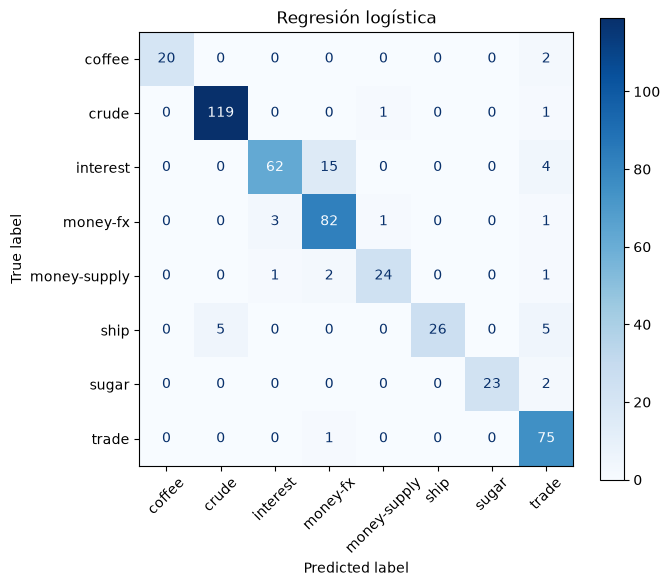

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, lr.predict(X_te), ax=ax, cmap="Blues", xticks_rotation=45)
ax.set_title("Regresión logística")
plt.show()

**Interpretación:**

- Incluso el clasificador por centroides, que solo guarda **un vector por clase**, logra una exactitud alta: la geometría del espacio TF-IDF separa bien los temas.
- kNN con $k=1$ es sensible al ruido (una sola noticia atípica decide); aumentar $k$ suele estabilizarlo hasta cierto punto.
- La regresión logística aprende **qué dimensiones** importan para cada clase, en lugar de tratar todas las palabras por igual como hace la similitud coseno, y por eso suele ser la mejor.
- La confusión más frecuente con diferencia es `interest` → `money-fx`: son temas de política monetaria que comparten vocabulario (*bank*, *rates*, *fed*, *dollar*). Le siguen noticias de `ship` clasificadas como `crude` o `trade`, porque hablan de petroleros, puertos o exportaciones. Son confusiones razonables que incluso un lector humano podría cometer con noticias cortas.

---

<a id="ejercicio-5"></a>
<h2 style="color: #007ACC;">Ejercicio 5. Vectores de palabras y el tamaño de la ventana</h2>

**Objetivo:** construir vectores de palabras PPMI + SVD y analizar cómo el tamaño de la ventana de contexto cambia el tipo de similitud capturada.

1. Tokeniza todas las noticias de **entrenamiento** (usa `CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{2,}\b").build_analyzer()`) y quédate con las 3 000 palabras más frecuentes.
2. Implementa `vectores_ppmi_svd(tokens_docs, vocab, ventana, dim=100)` que construya la matriz de co-ocurrencia (dispersa), aplique PPMI, reduzca con `TruncatedSVD` y devuelva los vectores normalizados.
3. Construye dos modelos: `ventana=2` y `ventana=10`.
4. Para las palabras `oil`, `coffee`, `bank`, `rose` y `tonnes`, muestra los 6 vecinos más cercanos en cada modelo.
5. ¿Qué diferencia observas entre las vecindades de ventana pequeña y grande? Relaciónalo con la diferencia entre similitud **sintáctica / funcional** y similitud **temática**.

In [10]:
analizador = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{2,}\b").build_analyzer()
tokens_docs = [analizador(t) for t in X_train_txt]
vocab = [w for w, _ in Counter(w for d in tokens_docs for w in d).most_common(3000)]
indice = {w: i for i, w in enumerate(vocab)}


def vectores_ppmi_svd(tokens_docs, vocab, ventana, dim=100):
    filas, cols = [], []
    for doc in tokens_docs:
        ids = [indice[w] for w in doc if w in indice]
        for p, i in enumerate(ids):
            for j in ids[max(0, p - ventana):p] + ids[p + 1:p + 1 + ventana]:
                filas.append(i)
                cols.append(j)
    V = len(vocab)
    C = sparse.coo_matrix((np.ones(len(filas)), (filas, cols)), shape=(V, V)).toarray()

    total = C.sum()
    p_w = C.sum(axis=1, keepdims=True) / total
    p_c = C.sum(axis=0, keepdims=True) / total
    with np.errstate(divide="ignore", invalid="ignore"):
        pmi = np.log((C / total) / (p_w * p_c))
    ppmi = np.where(np.isfinite(pmi), np.maximum(pmi, 0), 0)

    W = TruncatedSVD(n_components=dim, random_state=SEED).fit_transform(ppmi)
    return normalize(W)


W2 = vectores_ppmi_svd(tokens_docs, vocab, ventana=2)
W10 = vectores_ppmi_svd(tokens_docs, vocab, ventana=10)


def vecinos(W, palabra, k=6):
    sims = W @ W[indice[palabra]]
    return ", ".join(vocab[i] for i in np.argsort(-sims)[1:k + 1])


pd.DataFrame(
    {"ventana = 2": [vecinos(W2, p) for p in ["oil", "coffee", "bank", "rose", "tonnes"]],
     "ventana = 10": [vecinos(W10, p) for p in ["oil", "coffee", "bank", "rose", "tonnes"]]},
    index=["oil", "coffee", "bank", "rose", "tonnes"],
)

,ventana = 2,ventana = 10
oil,"crude, gas, barrels, prices, production, company","barrels, petroleum, crude, energy, bpd, gas"
coffee,"ico, export, quotas, colombia, brazil, ibc","ico, quotas, export, organization, colombia, bags"
bank,"rate, central, trust, banks, midland, barclays","lending, rate, pct, banks, rates, money"
rose,"fell, billion, grew, seasonally, provisional, adjusted","billion, fell, provisional, january, seasonally, grew"
tonnes,"sugar, whites, white, cuba, raw, cuban","sugar, raw, cuba, cuban, czarnikow, whites"


**Interpretación:**

- Con **ventana pequeña** el contexto son las palabras inmediatamente vecinas, que reflejan cómo **se usa** la palabra en la oración. Los vecinos tienden a ser palabras que podrían **sustituirla** en la misma posición. El ejemplo más claro es *bank*: con ventana 2 sus vecinos incluyen nombres de bancos (*midland*, *barclays*) y *trust*, que ocupan el mismo lugar en frases como *"... bank said"*. Con *rose*, ventana 2 agrupa verbos de cambio (*fell*, *grew*).
- Con **ventana grande** el contexto se acerca al documento entero y se captura la similitud **temática**: *bank* queda cerca de *lending*, *rates* y *money*, palabras de las mismas noticias aunque no sean intercambiables; *oil* se acerca a *petroleum*, *energy* y *bpd* (barriles por día).
- En otras palabras (*coffee*, *tonnes*) ambas ventanas dan resultados parecidos, porque en este corpus esas palabras aparecen casi siempre en el mismo tipo de noticia. Por ejemplo, *tonnes* queda pegada a *sugar* en los dos modelos.
- Esta misma disyuntiva existe en Word2Vec y GloVe (módulo 3): la ventana es un hiperparámetro que debe elegirse según si la tarea necesita similitud funcional (por ejemplo, etiquetado gramatical) o temática (por ejemplo, búsqueda o clasificación por tema).
- El corpus es pequeño y muy especializado, así que algunas vecindades son ruidosas; con más datos los patrones se vuelven más nítidos.

---

<a id="ejercicio-6"></a>
<h2 style="color: #007ACC;">Ejercicio 6. Tópicos latentes y visualización</h2>

**Objetivo:** usar LSA para descubrir tópicos latentes y visualizar las noticias en dos dimensiones.

1. Aplica `TruncatedSVD(n_components=50)` sobre `X_tr` (TF-IDF del ejercicio 4) y muestra los 8 términos con mayor peso de las primeras 6 componentes. Intenta ponerle un nombre a cada "tópico".
2. Proyecta las noticias de **prueba** a esas 50 dimensiones (con el SVD ajustado en entrenamiento) y luego a 2D con PCA. Grafica coloreando por categoría.
3. Entrena una `LogisticRegression` sobre las 50 dimensiones de LSA y compara su exactitud con la del modelo sobre TF-IDF completo del ejercicio 4. ¿Cuánta información se pierde al pasar de miles de dimensiones a 50?

In [11]:
svd = TruncatedSVD(n_components=50, random_state=SEED)
Z_tr = svd.fit_transform(X_tr)
Z_te = svd.transform(X_te)
terminos = vec.get_feature_names_out()

for i in range(6):
    print(f"Componente {i}: {', '.join(terminos[np.argsort(-svd.components_[i])[:8]])}")

Componente 0: said, bank, mln, pct, billion, dlrs, money, market
Componente 1: stg, money, bank, mln, england, fed, revised, billion
Componente 2: fed, says, dlrs, customer, repurchase, billion, sets, week
Componente 3: rate, pct, prime, effective, bank, rates, raises, base
Componente 4: crude, oil, bbl, cts, 50, dlrs, prices, barrel
Componente 5: january, billion, rose, sugar, tonnes, february, 1986, year


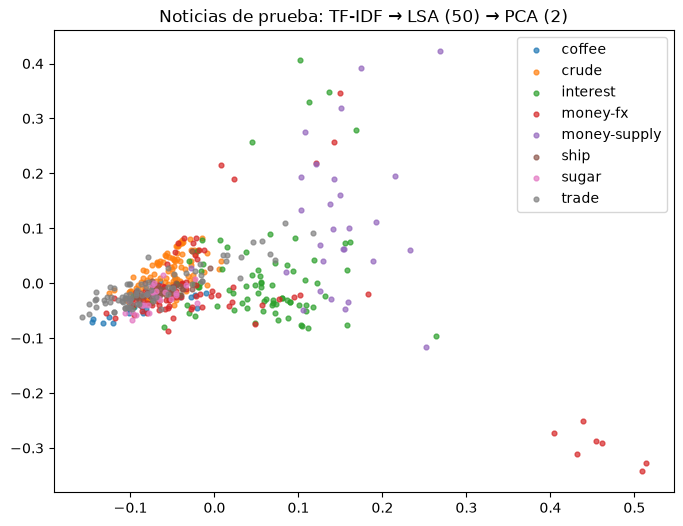

In [12]:
Z2 = PCA(n_components=2, random_state=SEED).fit(Z_tr).transform(Z_te)
plt.figure(figsize=(8, 6))
for c in clases:
    m = y_test == c
    plt.scatter(Z2[m, 0], Z2[m, 1], s=12, alpha=0.7, label=c)
plt.legend()
plt.title("Noticias de prueba: TF-IDF → LSA (50) → PCA (2)")
plt.show()

In [13]:
lr_lsa = LogisticRegression(max_iter=2000).fit(Z_tr, y_train)
print(f"Exactitud con 50 dimensiones LSA:      {accuracy_score(y_test, lr_lsa.predict(Z_te)):.3f}")
print(f"Exactitud con TF-IDF completo ({X_tr.shape[1]} dim): {resultados['regresión logística']:.3f}")

Exactitud con 50 dimensiones LSA:      0.889
Exactitud con TF-IDF completo (10973 dim): 0.905


**Interpretación:**

- La primera componente recoge el vocabulario más general del corpus (*said*, *mln*, *pct*). Las siguientes se alinean con temas reconocibles: mercado monetario británico (*stg*, *england*), operaciones de la Reserva Federal (*fed*, *repurchase*), tasas de interés (*prime*, *rates*), petróleo (*crude*, *bbl*, *barrel*) y estadísticas de azúcar (*sugar*, *tonnes*). LSA descubre estos **tópicos sin usar las etiquetas**.
- En la proyección 2D, temas con vocabulario muy propio (`coffee`, `sugar`, `crude`) forman grupos más compactos, mientras que los temas monetarios se solapan, consistente con la matriz de confusión del ejercicio 4.
- Pasar de casi 11 000 dimensiones a 50 conserva casi toda la información útil para clasificar: la exactitud cae menos de dos puntos. A cambio, los vectores son densos, pequeños y capturan relaciones entre términos que co-ocurren (sinónimos parciales), algo que la representación TF-IDF no puede hacer.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Lane, H., Howard, C. & Hapke, H. (2019). *Natural Language Processing in Action*. Manning.
- Documentación de scikit-learn: *Working With Text Data*. [scikit-learn.org](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
- Manning, C. D., Raghavan, P. & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press. [nlp.stanford.edu/IR-book](https://nlp.stanford.edu/IR-book/)